In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Reading the dataset.

In [66]:
df = pd.read_csv("/content/customer_churn_classification.csv")
df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,monthly_charges.1,tech_support,customer_id,gender,monthly_charges.2,monthly_charges.3,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,86.76,No,C10119,Male,86.76,86.76,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,109.03,No,C10012,Male,109.03,109.03,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,67.40,No,NaN,Female,67.40,67.40,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,81.81,NaN,NaN,ale,81.81,81.81,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,61.18,o,C10236,Fmale,61.18,61.18,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,51.0,26.0,Two year,DS,1286.98,101.71,101.71,NaN,C10203,Mal,101.71,101.71,0.0,Credit card
258,77.0,66.0,NaN,SL,6985.19,55.06,55.06,Yes,C10087,MALE,55.06,55.06,1.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,97.23,N,C10072,NaN,97.23,97.23,0.0,Credit card
260,48.0,62.0,MONTH-TO-MONTH,o,NaN,NaN,NaN,No,C10235,Female,NaN,NaN,NaN,Bank transfer


In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                233 non-null    float64
 1   tenure_months      241 non-null    float64
 2   contract           236 non-null    object 
 3   internet_service   240 non-null    object 
 4   total_charges      238 non-null    float64
 5   monthly_charges    233 non-null    float64
 6   monthly_charges.1  233 non-null    float64
 7   tech_support       238 non-null    object 
 8   customer_id        239 non-null    object 
 9   gender             242 non-null    object 
 10  monthly_charges.2  233 non-null    float64
 11  monthly_charges.3  233 non-null    float64
 12  churn              236 non-null    float64
 13  payment_method     245 non-null    object 
dtypes: float64(8), object(6)
memory usage: 28.8+ KB


**Numerical columns:** age, tenure_months, total_charges, monthly_charges, monthly_charges.1, monthly_charges.2, monthly_charges.3, churn

**Categorical columns:** contract, internet_service,tech_support, customer_id, gender, payment_method

# **Data Preprocessing**

#Removing the duplicate columns.

The columns monthly_charges.1, monthly_charges.2, monthly_charges.3 are duplicate columns.

In [68]:
df.drop(["monthly_charges.1", "monthly_charges.2", "monthly_charges.3"], axis=1, inplace = True)

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               233 non-null    float64
 1   tenure_months     241 non-null    float64
 2   contract          236 non-null    object 
 3   internet_service  240 non-null    object 
 4   total_charges     238 non-null    float64
 5   monthly_charges   233 non-null    float64
 6   tech_support      238 non-null    object 
 7   customer_id       239 non-null    object 
 8   gender            242 non-null    object 
 9   churn             236 non-null    float64
 10  payment_method    245 non-null    object 
dtypes: float64(5), object(6)
memory usage: 22.6+ KB


# **Filling the missing values.**



**NUMERICAL COLUMNS**

1. AGE COLUMN

Finding the unique elements in the age column.

---



In [70]:
df["age"].unique()

array([nan, 54., 34., 52., 36., 66., 53., 35., 20., 67., 55., 19., 21.,
       58., 43., 49., 23., 79., 48., 65., 76., 33., 77., 73., 47., 62.,
       39., 59., 42., 37., 61., 50., 18., 29., 32., 45., 56., 28., 75.,
       63., 24., 40., 41., 44., 25., 69., 68., 71., 31., 74., 46., 22.,
       78., 38., 64., 72., 26., 57., 70., 30., 51.])

Filling the missing values in age column with the mode.

In [71]:
df["age"]=df["age"].fillna(df["age"].mode()[0])

2. TENURE_MONTHS COLUMN

Finding the unique elements in the tenure_months column.

In [72]:
df["tenure_months"].unique()

array([34., 32., 49., 62., 24., nan,  0., 70., 60., 68., 35., 57., 51.,
       23., 56., 46., 11., 65.,  8., 54., 41., 61., 38., 33., 44., 45.,
        4., 12., 20., 25., 29., 59., 15., 27.,  9., 64., 14., 31., 16.,
       53., 28., 19., 30., 22.,  1., 58., 63., 37., 42., 48., 67., 52.,
        7., 21., 69., 13., 47.,  3., 18., 36., 43., 66., 26., 39.,  2.,
        6., 71.,  5., 55., 17., 50.])

Filling the missing values in the tenure_months columns using median.

In [73]:
df["tenure_months"] = df["tenure_months"].fillna(df["tenure_months"].median())

3. TOTAL_CHARGES COLUMN

Finding the unique elements in the total_charges column.

In [74]:
df["total_charges"].unique()

array([ 865.73, 3140.17, 3434.07,  341.26, 3236.51, 3312.22, 5956.66,
           nan, 1876.53, 1172.37, 7335.8 , 1931.38, 4087.27, 6802.33,
        406.95, 4645.14, 4804.3 , 6553.68,  627.14, 7285.91, 1798.88,
       2631.43, 5716.46, 1592.65, 4841.61, 3393.41, 2801.29, 3601.79,
       1359.57, 5281.08, 6462.26, 1286.32, 7696.35, 6147.18, 4001.96,
       3516.67, 7597.94, 7332.41, 4246.94, 5833.68, 6576.06, 1267.71,
        285.77,  723.2 , 5223.2 , 7172.36, 7216.68, 5944.27, 1821.51,
       3194.35, 1575.82, 1800.09, 1383.06, 7588.81, 1417.99, 2138.22,
       3625.25, 5036.57, 6403.09, 6874.43, 2311.81, 6393.4 , 4121.22,
       1810.09, 3305.72, 6418.9 , 4300.38, 7038.77, 7470.52, 2866.18,
       5375.59, 6675.71, 2290.9 , 2211.52, 3026.67, 4750.46, 5339.61,
       5808.56,  398.01, 2901.5 , 3727.3 , 2550.75, 5411.06, 4747.72,
       7270.48, 4811.95, 2896.43, 1567.9 , 2164.03, 7975.62, 4844.  ,
       6743.41, 5612.8 , 4565.19, 7507.27, 5068.36, 5376.64, 6605.81,
       2011.26, 5388

Filling the missing values in the total_charges column using the mean.

In [75]:
df["total_charges"] = df["total_charges"].fillna(df["total_charges"].mean())

4. MONTHLY_CHARGES COLUMN

Finding the unique values in the monthly_charges column.

In [77]:
df["monthly_charges"].unique()

array([ 86.76, 109.03,  67.4 ,  81.81,  61.18,  63.75,  88.15,  69.84,
        94.11,    nan,  27.59,  45.24,  83.34,  58.09,  73.71,  55.61,
        89.57, 110.42, 114.48, 109.05,  61.82,  72.02,  64.74,  33.98,
        43.72,  59.65,  35.29, 109.68,  47.69,  70.76,  71.4 ,  54.57,
        57.65,  61.04,  36.07, 104.18,  78.99,  22.01,  48.38,  48.86,
        81.06,  36.89,  57.05,  25.64, 114.98,  55.34,  60.35,  28.69,
        78.37,  52.88,  32.06,  81.34,  32.92,  56.89, 113.27, 115.04,
       111.09,  75.39,  52.21,  40.93,  36.26,  31.48,  82.21, 103.83,
        86.86, 101.06,  31.36,  56.31,  84.09,  41.14, 118.65, 106.55,
        32.89, 104.96,  89.04,  94.75, 103.06,  81.83,  34.71,  45.82,
        82.01,  31.98,  94.54, 117.44,  59.22,  53.66, 119.66,  24.09,
        41.3 , 101.29, 112.95, 112.09,  38.12,  80.58,  35.19, 113.83,
        35.04,  66.37,  65.45,  37.34,  66.87,  44.6 ,  48.  ,  87.17,
        87.16, 100.99,  56.43,  69.26,  32.43, 119.97, 119.  , 114.95,
      

Filling the missing values in the monthly_charges column using mean.

In [78]:
df["monthly_charges"] = df["monthly_charges"].fillna(df["monthly_charges"].mean())

5. CHURN COLUMN

Finding the unique elements in the churn column.

In [82]:
df["churn"].unique()

array([ 1.,  0., nan])

Filling the missing values in the churn column using mode because it has **numerical discrete** data.

In [83]:
df["churn"] = df["churn"].fillna(df["churn"].mode()[0])

# **CATEGORICAL COLUMNS**

CONTRACT COLUMN

Finding the missing values in contarct column.

In [85]:
df["contract"].unique()

array([nan, 'Month-to-month', 'Two year', 'ONE YEAR', 'Two yer',
       'MONTH-TO-MONTH', 'Twoyear', 'Monh-to-month', 'One year',
       'Month-t-month', 'Moth-to-month', 'TWO YEAR', 'ne year',
       'onth-to-month', 'Monthto-month', 'One ear', 'wo year', 'To year',
       'Month-to-monh', 'Two yea', 'Month-o-month', 'Oe year',
       'Month-to-mont', 'On year', 'One yea', 'Oneyear', 'Month-to-moth'],
      dtype=object)

Removing the inconsistency in contract column.

In [96]:
df["contract"].replace(["ONE YEAR" , "One year", "ne year", "One ear", "Oe year", "On year", "One yea", "Oneyear"], "One Year", inplace=True)

In [97]:
df["contract"].replace(["Two year", "Two yer", "Twoyear", "TWO YEAR", "wo year", "To year", "Two yea"], "Two Year", inplace=True)

In [100]:
df['contract'].replace(["MONTH-TO-MONTH", "Monthly", "Month-to-month", "MONTH_TO_MONTH" , "Monh-to-month", "Month-t-month" , "Moth-to-month", "onth-to-month" , "Monthto-month", "Month-to-monh", "Month-o-month", "Month-to-mont", "Month-to-moth"],"Monthly", inplace=True)

In [101]:
df["contract"].unique()

array([nan, 'Monthly', 'Two Year', 'One Year'], dtype=object)

Filling the missing values in the contract column using mode.

In [103]:
df["contract"] = df["contract"].fillna(df["contract"].mode()[0])

INTERNET_SERVICE COLUMN

Finding the unique values present in internet_service column.

In [105]:
df["internet_service"].unique()

array(['No', nan, 'Fiber optic', 'DSL', 'FIBER OPTIC', 'Fiber opti', 'DS',
       'Fiber ptic', 'o', 'Dsl', 'NO', 'SL', 'Fiber optc', 'N',
       'iber optic', 'DL', 'Fibe optic', 'Fiber opic', 'Fiberoptic'],
      dtype=object)

Removing the inconsistent data in internet_service column.

In [111]:
df["internet_service"].replace(["NO", "o", "N"] , "No", inplace = True)
df["internet_service"].replace(["Fiber optic", "Fiber ptic", "FIBER OPTIC", "Fiber opti", "FIber ptic", "Fiber optc", "iber optic", "Fibe optic", "Fiber opic", "Fiberoptic"], "Fiber Optic", inplace = True)
df["internet_service"].replace(["DS", "Dsl", "SL", "DL"], "DSL", inplace = True)

In [110]:
df["internet_service"].unique()

array(['No', nan, 'Fiber Optic', 'DSL'], dtype=object)

Filling the missing values using ffill.

In [117]:
df["internet_service"] = df["internet_service"].fillna(df["internet_service"].mode()[0])

TECH_SUPPORT COLUMN

In [119]:
df["tech_support"].unique()

array(['No', nan, 'o', 'Ys', 'NO', 'Yes', 'Ye', 'N', 'YES', 'es'],
      dtype=object)

Removing the inconsistency

In [120]:
df["tech_support"].replace(["o","NO","N"],"No", inplace=True)
df["tech_support"].replace(["Ys","Ye","YES","es"], "Yes", inplace = True)

/tmp/ipykernel_981/3997925696.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["tech_support"].replace(["o","NO","N"],"No", inplace=True)


In [121]:
df["tech_support"].unique()

array(['No', nan, 'Yes'], dtype=object)

Filling the missing values in the tech_supprot column usinf ffill().

In [128]:
df["tech_support"].ffill(inplace = True)

GENDER COLUMN

In [132]:
df["gender"].unique()

array(['Male', 'Female', nan, 'FEMALE'], dtype=object)

In [133]:
df["gender"].replace(["ale","MALE","Mae","Mle","Mal"],"Male", inplace = True)
df["gender"].replace(["Fmale","FEMALE","emale","Feale","Femae","Femal","Femle"], "Female", inplace =True)

Filling the missing values using bfill.

In [134]:
df["gender"].bfill(inplace = True)

PAYMENT METHOD

In [136]:
df["payment_method"].unique()

array(['Mailed check', 'ELECTRONIC CHECK', 'Electronic check',
       'Electroni check', nan, 'Mailed ceck', 'Bank transfer',
       'Credt card', 'Credit card', 'MAILED CHECK', 'CREDIT CARD',
       'Cedit card', 'Bak transfer', 'BANK TRANSFER', 'Credit cad',
       'Bank tranfer', 'Crdit card', 'Maled check', 'Maild check',
       'Bank ransfer', 'Credit ard', 'Credit car', 'Bank transfe',
       'Electrnic check', 'Ban transfer', 'Eletronic check', 'Creditcard',
       'Creit card'], dtype=object)

In [143]:
df["payment_method"].replace(["Mailed check", "Mailed ceck","MAILED CHECK","Maled check", "Maild check"], "Mailed Check", inplace= True)
df["payment_method"].replace(["ELECTRONIC CHECK", "Electronic check", "Electroni check", "Electrnic check","Eletronic check", "letronic check"], "Electronic Check", inplace = True)
df["payment_method"].replace(["Bank transfer", "Bak transfer", "BANK TRANSFER", "Bank tranfer", "Bank ransfer", "Bank transfe", "Ban transfer"], "Bank Transfer", inplace =True)
df["payment_method"].replace(["Credt card", "Credit card","CREDIT CARD", "Cedit card","Credit cad", "Crdit card" ,"Credit ard","Credit car", "Creditcard","Creit card"], "Credit Card", inplace = True)

In [144]:
df["payment_method"].unique()

array(['Mailed Check', 'Electronic Check', nan, 'Bank Transfer',
       'Credit Card'], dtype=object)

In [147]:
df["payment_method"] = df["payment_method"].fillna(df["payment_method"].mode()[0])

In [148]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               262 non-null    float64
 1   tenure_months     262 non-null    float64
 2   contract          262 non-null    object 
 3   internet_service  262 non-null    object 
 4   total_charges     262 non-null    float64
 5   monthly_charges   262 non-null    float64
 6   tech_support      262 non-null    object 
 7   customer_id       239 non-null    object 
 8   gender            262 non-null    object 
 9   churn             262 non-null    float64
 10  payment_method    262 non-null    object 
dtypes: float64(5), object(6)
memory usage: 22.6+ KB


**Dropping the customer_id column and creating a new column using np.range() function for the values.**

In [151]:
df = df.drop("customer_id", axis =  1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               262 non-null    float64
 1   tenure_months     262 non-null    float64
 2   contract          262 non-null    object 
 3   internet_service  262 non-null    object 
 4   total_charges     262 non-null    float64
 5   monthly_charges   262 non-null    float64
 6   tech_support      262 non-null    object 
 7   gender            262 non-null    object 
 8   churn             262 non-null    float64
 9   payment_method    262 non-null    object 
dtypes: float64(5), object(5)
memory usage: 20.6+ KB


In [153]:
df["customer_id"] = np.arange(1,263)

In [155]:
df["customer_id"].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

**Key Restructuring**

In [158]:
df.columns = df.columns.str.title()

# **Preprocessed Dataset**

In [159]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               262 non-null    float64
 1   Tenure_Months     262 non-null    float64
 2   Contract          262 non-null    object 
 3   Internet_Service  262 non-null    object 
 4   Total_Charges     262 non-null    float64
 5   Monthly_Charges   262 non-null    float64
 6   Tech_Support      262 non-null    object 
 7   Gender            262 non-null    object 
 8   Churn             262 non-null    float64
 9   Payment_Method    262 non-null    object 
 10  Customer_Id       262 non-null    int64  
dtypes: float64(5), int64(1), object(5)
memory usage: 22.6+ KB


Saving the preprocessed dataset into preprocessed_dataset.csv file.

In [161]:
df.to_csv("preprocessed_dataset.csv")

# **Data Analysis**

Reading the csv file

In [163]:
df1 = pd.read_csv("/content/preprocessed_dataset.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               262 non-null    float64
 1   Tenure_Months     262 non-null    float64
 2   Contract          262 non-null    object 
 3   Internet_Service  262 non-null    object 
 4   Total_Charges     262 non-null    float64
 5   Monthly_Charges   262 non-null    float64
 6   Tech_Support      262 non-null    object 
 7   Gender            262 non-null    object 
 8   Churn             262 non-null    float64
 9   Payment_Method    262 non-null    object 
 10  Customer_Id       262 non-null    int64  
dtypes: float64(5), int64(1), object(5)
memory usage: 22.6+ KB


**Count plot of Payment Method**

Most of the customers prefer the CREDIT CARD payment method.

/tmp/ipykernel_981/844822151.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Payment_Method", palette = "Set2")


<Axes: xlabel='Payment_Method', ylabel='count'>

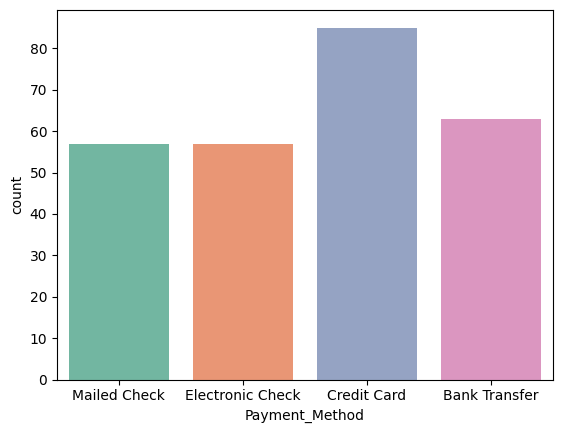

In [230]:
sns.countplot(data=df, x="Payment_Method", palette = "Set2")

# UNIVARIATE ANALYSIS

The observation that can be made from the below graph is that
Customers within the age range of 50-60 uses internet service.
Customers within the age range of 25-30 are less likely to use the internet services.

Text(0.5, 1.0, 'Frequency of the customers based on age')

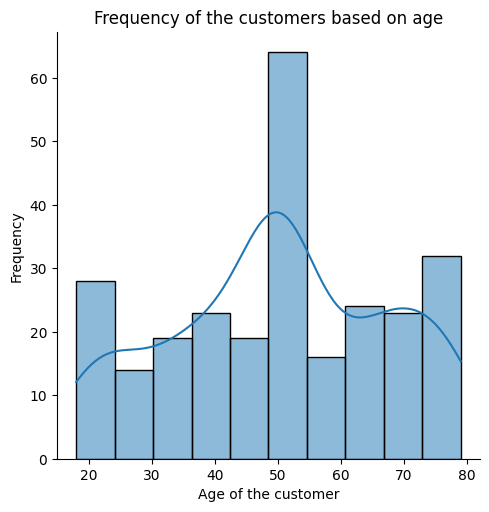

In [176]:
sns.displot(data = df, x="Age", kde = True)
plt.xlabel("Age of the customer")
plt.ylabel("Frequency")
plt.title("Frequency of the customers based on age")

***PIE CHART***

From the below graph we can observe that the customers prefer mothly contract the most and one year contract the least.

Text(0.5, 1.0, 'Distribution of contract periods')

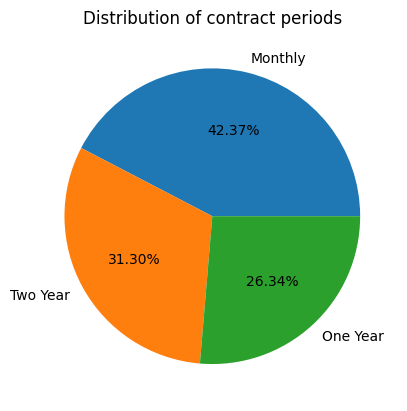

In [181]:
contract_count = df["Contract"].value_counts()
plt.pie(contract_count.values, labels = contract_count.index , autopct = "%1.2f%%")
plt.title("Distribution of contract periods")

Text(0.5, 1.0, 'Selection frequency of Internet Service')

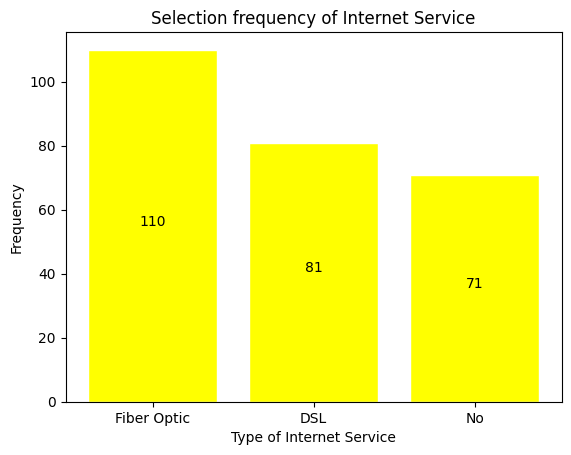

In [188]:
service_count = df["Internet_Service"].value_counts()
bar_chart = plt.bar(service_count.index, service_count.values, color = "yellow", edgecolor= "white")
plt.bar_label(bar_chart, padding = 3, label_type= "center")
plt.xlabel("Type of Internet Service")
plt.ylabel("Frequency")
plt.title("Selection frequency of Internet Service")

<BarContainer object of 2 artists>

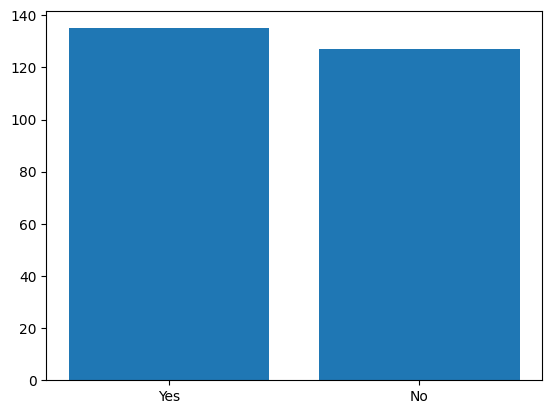

In [227]:
support = df["Tech_Support"].value_counts()
plt.bar(support.index, support.values)

# **BIVARIATE ANALYSIS**

Text(0.5, 1.0, 'Churn count based on gender')

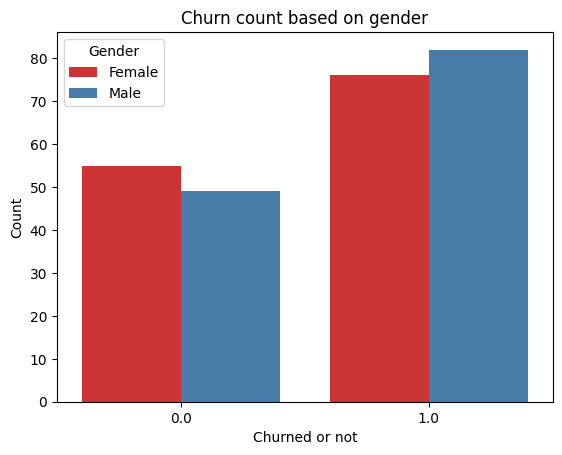

In [202]:
sns.countplot(data = df1, x="Churn", hue="Gender", palette = "Set1")
plt.xlabel("Churned or not")
plt.ylabel("Count")
plt.title("Churn count based on gender")

The observations that can be made from the below graph are:
The customers with the age nearly 45 are more likely to churn.
The customers with the age nearly 60 are least likely to churn.

<Axes: xlabel='Churn', ylabel='count'>

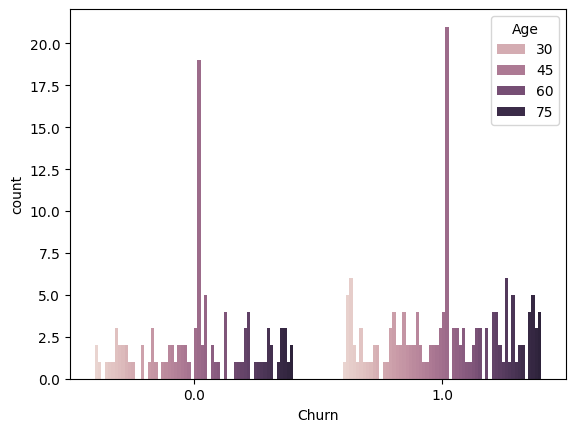

In [225]:
sns.countplot(data = df1, x="Churn" , hue = "Age")

# BOX PLOT

The median value of the monthly charges is nearly 70 and the values are in the range of 20 and 120.

Text(0.5, 0, 'Monthly charges')

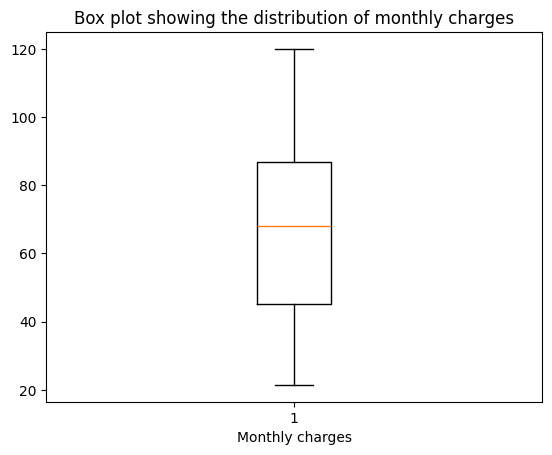

In [210]:
plt.boxplot(df["Monthly_Charges"])
plt.title("Box plot showing the distribution of monthly charges")
plt.xlabel("Monthly charges")

The median value of the monthly charges is nearly 4000 and the values are in the range of 200 and 8000.

Text(0.5, 0, 'Total charges')

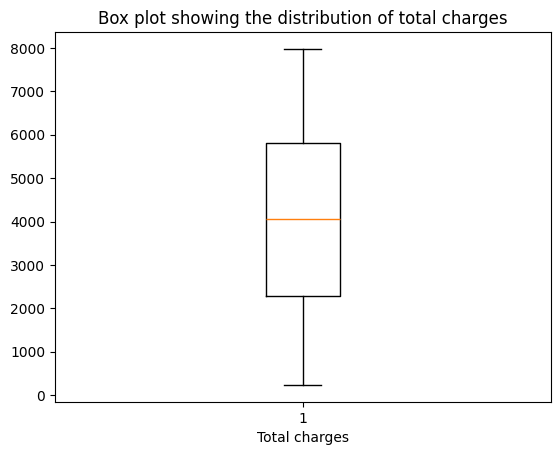

In [211]:
plt.boxplot(df["Total_Charges"])
plt.title("Box plot showing the distribution of total charges")
plt.xlabel("Total charges")

# **MULTI VARIATE ANALYSIS**

HeatMap

Observations:
The total_charges and monthly_charges are negatively correlated.

Text(0.5, 1.0, 'Heatmap showing the correlations between all the numerical columns')

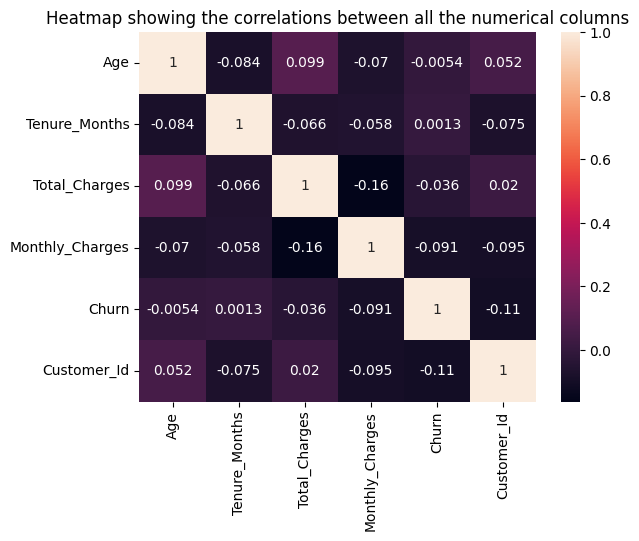

In [216]:
sns.heatmap(df.corr(numeric_only = True), annot = True)
plt.title("Heatmap showing the correlations between all the numerical columns")

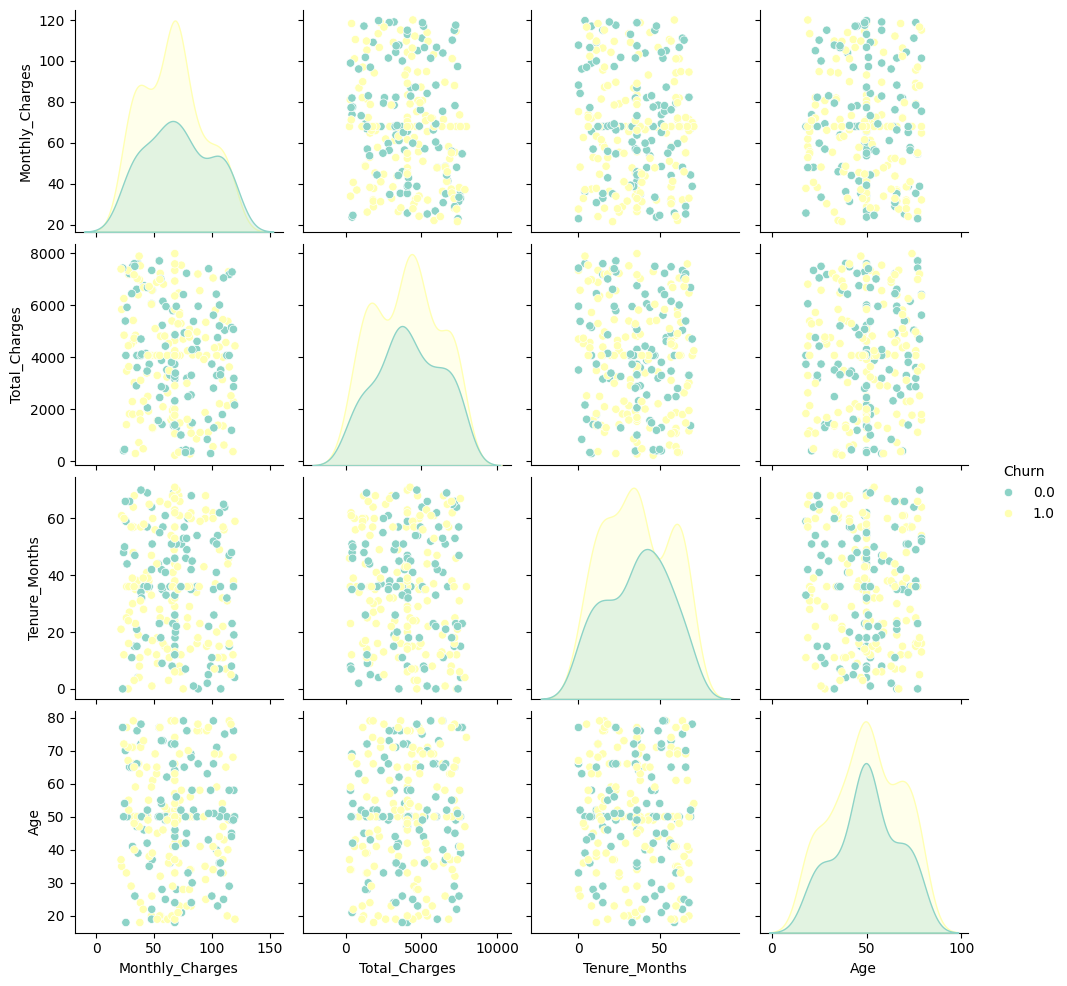

In [219]:
sns.pairplot(data =df, vars = ["Monthly_Charges", "Total_Charges", "Tenure_Months", "Age"], hue = "Churn", palette = "Set3")

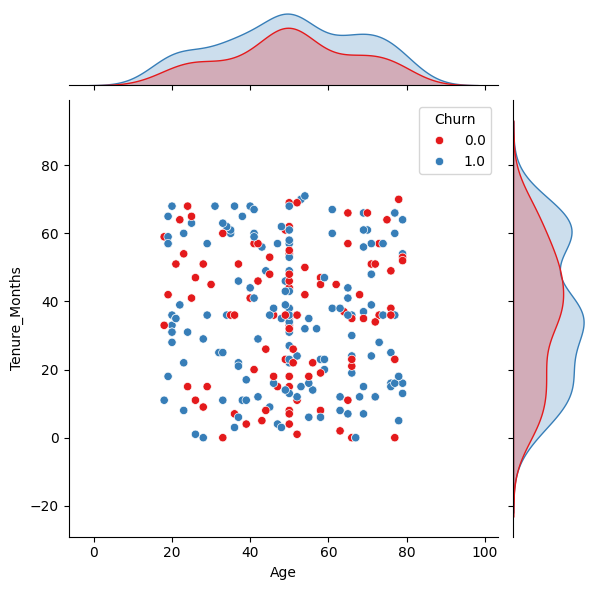

In [220]:
sns.jointplot(data = df, x="Age", y="Tenure_Months", hue = "Churn", palette = "Set1")

**Report:**

From the above performed data analysis , it can be concluded that:


*   Majority of the **men** and customers with the **age approximately 45** are more likely to **churn** i.e disconnected.
*   The technical support can be slightly improved.
*   Customers who prefer yearly plan have high chances of disconnection.
*   The **monthly** plan is **mostly preferred**.
*   The most selected payment method is **Credit Card**.





